# FinMark Corporation: Data Visualization Workflow
## Milestone 2 — Team PETIX

This notebook builds on the cleaned datasets and exploratory analysis
completed in Milestone 1. It uses NumPy for numerical computations and
Matplotlib and Seaborn to explore customer ages, transaction amounts,
product categories, monthly record counts, and social media sentiment.

The analysis uses datasets that exclude unresolved primary-ID conflicts.
Age analyses use observed ages rather than median-imputed values.
Amount analyses use nonmissing, nonnegative amounts, including zero values.

The visualizations describe the available records and identify
considerations for future machine learning. They do not establish
cause-and-effect relationships or demonstrate predictive model performance.

In [22]:
# Install dependencies first: python -m pip install -r requirements.txt


Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Set a consistent style for our charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("All libraries imported successfully!")
print("Current folder:", Path.cwd())

All libraries imported successfully!
Current folder: c:\Users\Asus\H3101-ML-ml-linear-algebra-project-Team-PETIX--main\H3101-ML-ml-linear-algebra-project-Team-PETIX--main\H3101-ML-ml-linear-algebra-project-Team-PETIX--main\Week3_Preprocessing_Submission


In [3]:
# Locate the analysis datasets
data_folder = Path.cwd() / "data_eda"

if not data_folder.is_dir():
    raise FileNotFoundError(
        f"Cannot find data_eda in {Path.cwd()}. Check the project folder."
    )

# Load the MS1 analysis datasets
demographics = pd.read_csv(
    data_folder / "customer_demographics_eda.csv"
)
transactions = pd.read_csv(
    data_folder / "customer_transactions_eda.csv"
)
amount_data = pd.read_csv(
    data_folder / "customer_transactions_amount_eda.csv"
)
social_media = pd.read_csv(
    data_folder / "social_media_interactions_eda.csv"
)

In [4]:
# Group the loaded datasets
datasets = {
    "Demographics": demographics,
    "Transactions": transactions,
    "Valid transaction amounts": amount_data,
    "Social media": social_media,
}

# Inspect dataset sizes, column names, and data types
for name, df in datasets.items():
    print(f"\n{name} — {len(df):,} rows")
    print(df.dtypes.to_string())


Demographics — 2,977 rows
CustomerID         str
Age            float64
Gender             str
Location           str
IncomeLevel        str
SignupDate         str
IDConflict        bool
AgeOriginal        str
AgeStatus          str
AgeObserved    float64
AgeImputed        bool

Transactions — 2,985 rows
CustomerID             str
TransactionID          str
TransactionDate        str
Amount             float64
ProductCategory        str
PaymentMethod          str
IDConflict            bool
AmountOriginal         str
AmountStatus           str

Valid transaction amounts — 2,642 rows
CustomerID             str
TransactionID          str
TransactionDate        str
Amount             float64
ProductCategory        str
PaymentMethod          str
IDConflict            bool
AmountOriginal     float64
AmountStatus           str

Social media — 2,980 rows
CustomerID            str
InteractionID         str
InteractionDate       str
Platform              str
InteractionType       str
Sentiment 

In [5]:
# Use observed ages and the separate valid-amount dataset
ages = demographics["AgeObserved"].dropna().to_numpy()
amounts = amount_data["Amount"].dropna().to_numpy()

print("Observed ages:", len(ages))
print("Valid amounts:", len(amounts))
print("Social media records:", len(social_media))

print("Ages outside 18–100:", np.sum((ages < 18) | (ages > 100)))
print("Negative amounts:", np.sum(amounts < 0))
print("Zero amounts retained:", np.sum(amounts == 0))

Observed ages: 2615
Valid amounts: 2642
Social media records: 2980
Ages outside 18–100: 0
Negative amounts: 0
Zero amounts retained: 28


In [6]:
# Numerical summaries using NumPy
def numerical_summary(values):
    q1, q3 = np.percentile(values, [25, 75])

    return {
        "Count": len(values),
        "Mean": np.mean(values),
        "Median": np.median(values),
        "Standard deviation (sample)": np.std(values, ddof=1),
        "Variance (sample)": np.var(values, ddof=1),
        "Minimum": np.min(values),
        "Maximum": np.max(values),
        "Range": np.ptp(values),
        "25th percentile (Q1)": q1,
        "75th percentile (Q3)": q3,
        "Interquartile range (IQR)": q3 - q1,
    }

numerical_stats = pd.DataFrame({
    "Observed Age": numerical_summary(ages),
    "Valid Amount": numerical_summary(amounts),
})

display(numerical_stats.round(2))

,Observed Age,Valid Amount
Count,2615.00,2642.00
Mean,44.59,499.03
Median,45.00,503.66
Standard deviation (sample),15.42,292.46
Variance (sample),237.81,85533.17
Minimum,18.00,0.00
Maximum,70.00,999.86
Range,52.00,999.86
25th percentile (Q1),31.00,237.98
75th percentile (Q3),58.00,749.18


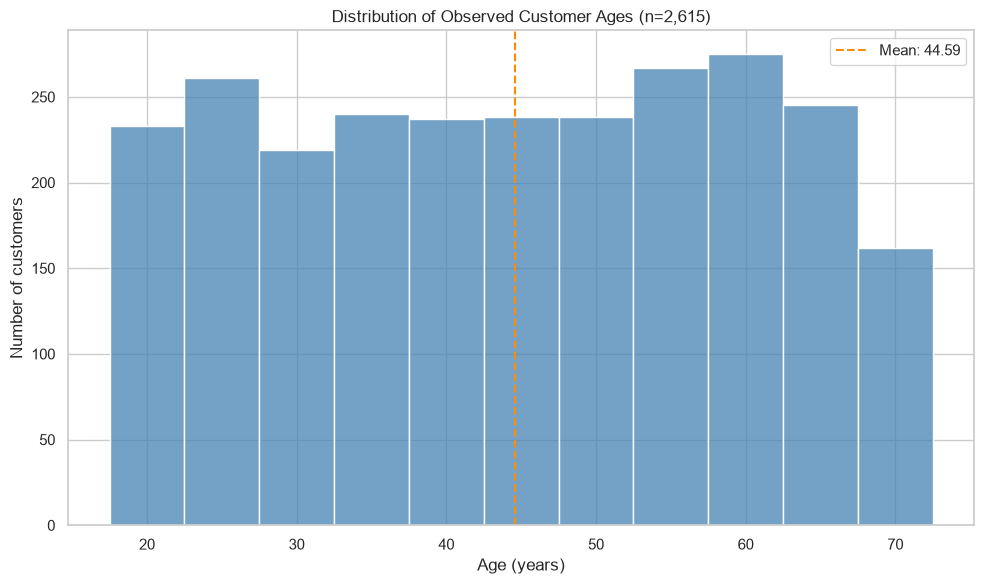

In [7]:
# Create a folder for exported charts
figures_folder = Path.cwd() / "figures"
figures_folder.mkdir(exist_ok=True)

# Plot observed ages only
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    x=ages,
    bins=np.arange(17.5, 73, 5),
    color="steelblue",
    edgecolor="white",
    ax=ax
)

ax.axvline(
    np.mean(ages),
    color="darkorange",
    linestyle="--",
    label=f"Mean: {np.mean(ages):.2f}"
)

ax.set_title(f"Distribution of Observed Customer Ages (n={len(ages):,})")
ax.set_xlabel("Age (years)")
ax.set_ylabel("Number of customers")
ax.legend()

fig.tight_layout()
fig.savefig(
    figures_folder / "01_observed_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Observed Age Distribution

A histogram was used to show how customer ages are distributed across
five-year intervals. The analysis includes 2,615 observed ages and excludes
median-imputed ages.

Observed ages range from 18 to 70, with a mean of 44.59 and a median of 45.
The 58–62 interval has the highest count at 275 customers (10.52%).
The complete five-year intervals have relatively similar counts, with no
single interval strongly dominating.

The final interval, 68–72, contains observed ages only from 68 to 70,
which should be considered when comparing its lower count.

For future machine learning, this chart helps assess age coverage.
It does not establish whether age predicts customer behavior.

In [8]:
# Count observations in the same intervals used in the histogram
age_bins = np.arange(17.5, 73, 5)
counts, edges = np.histogram(ages, bins=age_bins)

age_frequency = pd.DataFrame({
    "Age interval": [
        f"{int(left + 0.5)}–{int(right - 0.5)}"
        for left, right in zip(edges[:-1], edges[1:])
    ],
    "Count": counts,
    "Percentage": np.round(counts / len(ages) * 100, 2)
})

display(age_frequency)

,Age interval,Count,Percentage
0,18–22,233,8.91
1,23–27,261,9.98
2,28–32,219,8.37
3,33–37,240,9.18
4,38–42,237,9.06
5,43–47,238,9.10
6,48–52,238,9.10
7,53–57,267,10.21
8,58–62,275,10.52
9,63–67,245,9.37


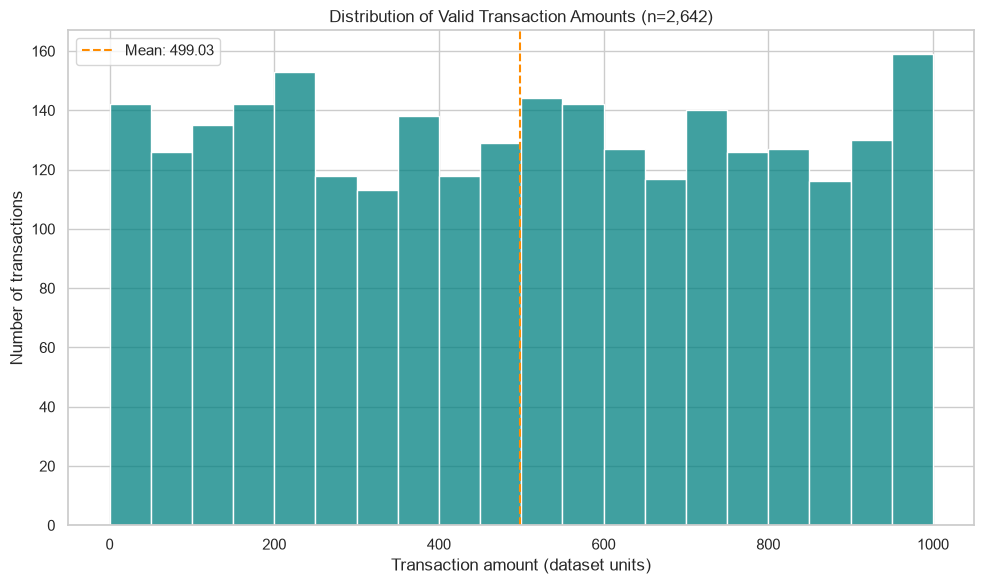

In [9]:
# Distribution of valid transaction amounts, including zeros
fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    x=amounts,
    bins=20,
    color="teal",
    edgecolor="white",
    ax=ax
)

ax.axvline(
    np.mean(amounts),
    color="darkorange",
    linestyle="--",
    label=f"Mean: {np.mean(amounts):.2f}"
)

ax.set_title(f"Distribution of Valid Transaction Amounts (n={len(amounts):,})")
ax.set_xlabel("Transaction amount (dataset units)")
ax.set_ylabel("Number of transactions")
ax.legend()

fig.tight_layout()
fig.savefig(
    figures_folder / "02_transaction_amount_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Transaction Amount Distribution

A histogram was used to examine the distribution of 2,642 nonmissing,
nonnegative transaction amounts. Zero amounts were retained.

Amounts range from 0 to 999.86 dataset units. The mean is 499.03,
the median is 503.66, and the sample standard deviation is 292.46.

The amounts are spread relatively evenly across the displayed intervals.
Although the mean and median are near 500, this does not mean that most
transactions are concentrated around that amount.

For future machine learning, the spread of transaction amounts can help
inform decisions about scaling numerical features. The chart alone does
not establish which amounts are unusual or incorrect.

,Count,Percentage
ProductCategory,,
Clothing,565,18.93
Electronics,558,18.69
Automotive,536,17.96
Home & Garden,528,17.69
Health & Beauty,520,17.42
Unknown,278,9.31


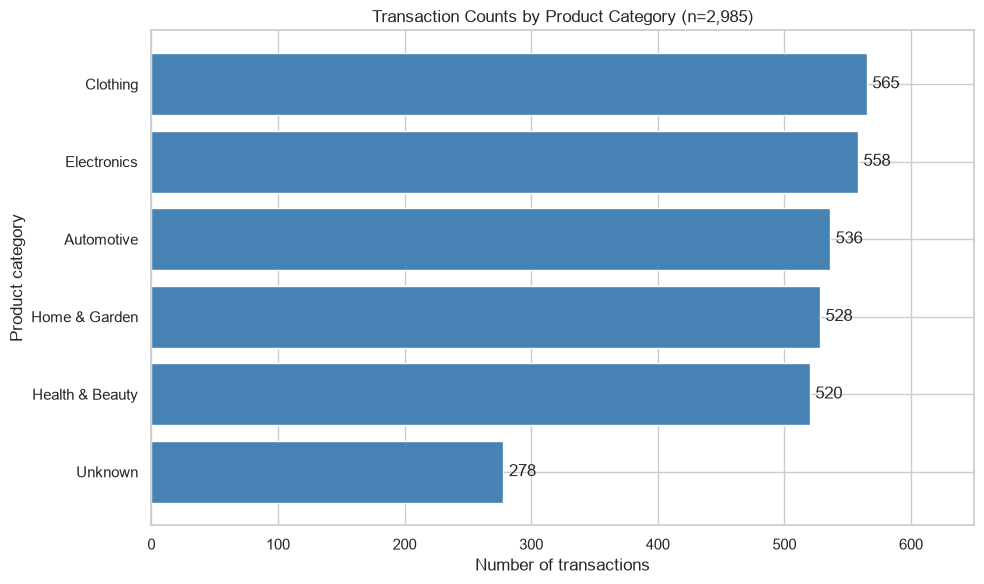

In [10]:
# Count transactions per product category
category_counts = (
    transactions["ProductCategory"]
    .fillna("Unknown")
    .value_counts()
)

display(pd.DataFrame({
    "Count": category_counts,
    "Percentage": (category_counts / len(transactions) * 100).round(2)
}))

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

ax.barh(
    category_counts.index,
    category_counts.values,
    color="steelblue"
)
ax.invert_yaxis()

ax.bar_label(ax.containers[0], padding=4)
ax.set_xlim(0, category_counts.max() * 1.15)
ax.set_title(f"Transaction Counts by Product Category (n={len(transactions):,})")
ax.set_xlabel("Number of transactions")
ax.set_ylabel("Product category")

fig.tight_layout()
fig.savefig(
    figures_folder / "03_product_category_counts.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Product Category Counts

A horizontal bar chart was used to compare transaction counts across
product categories. It includes all 2,985 transaction records in the
analysis dataset.

Clothing has the highest count at 565 transactions (18.93%), followed
by Electronics with 558 (18.69%). The five named categories have similar
counts, ranging from 520 to 565, so no named category strongly dominates.

Unknown accounts for 278 transactions (9.31%). This represents records
without an available category label and should be considered separately
when interpreting product preferences.

For future machine learning, these counts help assess category balance
and highlight missing category information. They describe transaction
frequency rather than total spending or individual customer preferences.

,count,median,mean
ProductCategory,,,
Home & Garden,469,524.62,525.16
Automotive,479,519.57,504.45
Electronics,492,510.75,494.53
Clothing,498,507.66,500.67
Health & Beauty,455,466.14,478.96
Unknown,249,461.82,481.64


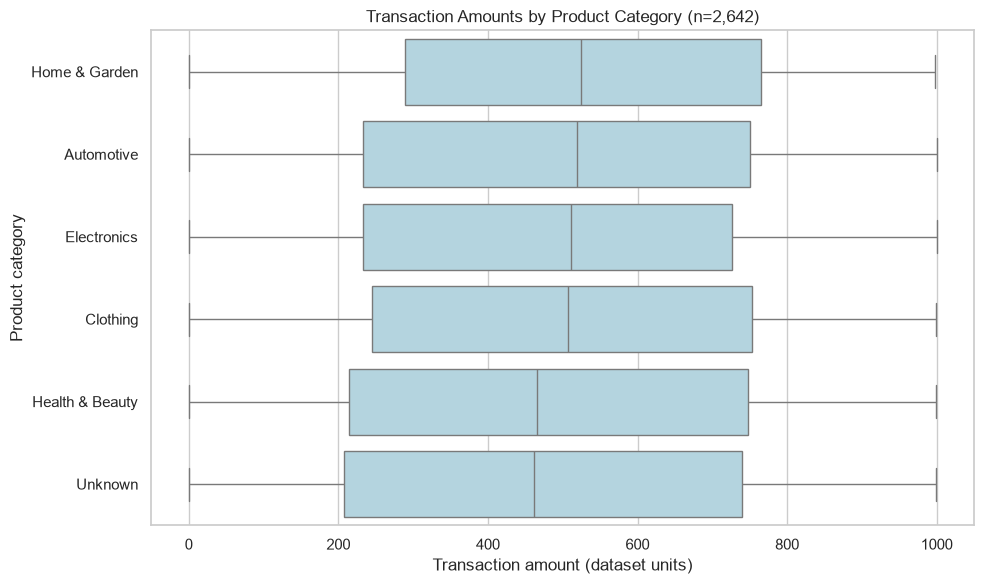

In [11]:
# Use only records with valid amounts
plot_data = amount_data.copy()
plot_data["ProductCategory"] = (
    plot_data["ProductCategory"].fillna("Unknown")
)

# Show the supporting counts and statistics
category_summary = (
    plot_data.groupby("ProductCategory")["Amount"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

display(category_summary.round(2))

# Compare amount distributions
fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=plot_data,
    x="Amount",
    y="ProductCategory",
    order=category_summary.index,
    color="lightblue",
    whis=1.5,
    ax=ax
)

ax.set_title(
    f"Transaction Amounts by Product Category (n={len(plot_data):,})"
)
ax.set_xlabel("Transaction amount (dataset units)")
ax.set_ylabel("Product category")

fig.tight_layout()
fig.savefig(
    figures_folder / "04_amount_by_product_category.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Transaction Amounts by Product Category

A box plot was used to compare median transaction amounts, their spread,
and potential outliers across product categories. This chart uses the
2,642 records with nonmissing, nonnegative amounts.

Home & Garden has the highest median amount at 524.62 dataset units.
Health & Beauty has the lowest median among the named categories at
466.14. The Unknown group has a median of 461.82.

The boxes and whiskers overlap considerably, showing that transaction
amounts vary widely within each category. Differences in medians alone
do not establish that product category strongly predicts transaction amount.

The separate numerical check found no outliers within any category
using the 1.5 × IQR rule. This does not guarantee that every record is
accurate; it means no amounts exceeded the thresholds used.

For future machine learning, product category can be explored alongside
other variables, with its usefulness assessed through model evaluation.

In [12]:
# Check potential outliers within each product category
outlier_results = []

for category, group in plot_data.groupby("ProductCategory"):
    values = group["Amount"].to_numpy()
    q1, q3 = np.percentile(values, [25, 75])
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    flagged = (values < lower) | (values > upper)

    outlier_results.append({
        "Product category": category,
        "Lower fence": lower,
        "Upper fence": upper,
        "Potential outliers": np.sum(flagged)
    })

display(pd.DataFrame(outlier_results).round(2))

,Product category,Lower fence,Upper fence,Potential outliers
0,Automotive,-544.17,1527.94,0
1,Clothing,-517.89,1515.95,0
2,Electronics,-506.69,1466.66,0
3,Health & Beauty,-585.10,1547.20,0
4,Home & Garden,-423.68,1478.04,0
5,Unknown,-590.65,1538.20,0


In [13]:
# Convert exported date strings back into dates
transactions["TransactionDate"] = pd.to_datetime(
    transactions["TransactionDate"],
    errors="coerce"
)

print("Total transaction records:", len(transactions))
print("Missing or unparseable dates:",
      transactions["TransactionDate"].isna().sum())
print("Earliest date:", transactions["TransactionDate"].min())
print("Latest date:", transactions["TransactionDate"].max())

# Count records by month
monthly_counts = (
    transactions.dropna(subset=["TransactionDate"])
    .groupby(transactions["TransactionDate"].dt.to_period("M"))
    .size()
)

display(monthly_counts.rename("Transaction count").to_frame())

Total transaction records: 2985
Missing or unparseable dates: 0
Earliest date: 2022-01-07 00:00:00
Latest date: 2024-12-06 00:00:00


,Transaction count
TransactionDate,
2022-01,3
2022-03,1
2022-04,1
2022-05,1
2022-06,1
2022-07,113
2022-08,109
2022-09,119
2022-10,120


In [14]:
# Inspect dates outside the main concentration of records
outside_main_period = transactions.loc[
    (transactions["TransactionDate"] < "2022-07-01")
    | (transactions["TransactionDate"] >= "2024-07-01"),
    ["TransactionID", "TransactionDate"]
].sort_values("TransactionDate")

display(outside_main_period)
print("Records outside the main period:", len(outside_main_period))

,TransactionID,TransactionDate
2379,aee21c96-febd-4906-9881-12e32030e7f4,2022-01-07
872,181ad5a0-fb64-470c-9e97-5dbd7a938afc,2022-01-08
2004,cc60f6b0-4598-4fab-8083-cb39d771e44c,2022-01-11
2220,13e60003-b968-45fd-8054-2f883c124c9f,2022-03-09
1660,4cd1f1f4-3efd-4bf0-8bc3-f0b248650488,2022-04-11
783,3292fdfd-806c-4226-bfed-4649f18ad018,2022-05-07
502,a42657eb-b99d-4b66-b0e7-96a9cd6def89,2022-06-07
2926,b4a5dcda-c2d0-4853-8db3-400127521eb4,2024-10-05
937,4e8da5ae-dd89-4fd1-85a4-d3341a97024d,2024-11-04
601,64f3ee25-c285-41ee-92b6-f70b006554ae,2024-12-06


Records outside the main period: 11


In [15]:
# Compare the flagged records with their original Excel dates
raw_transactions = pd.read_excel(
    Path.cwd() / "data_raw"
    / "customer_transactions_contaminated.xlsx"
)

raw_date_check = raw_transactions[
    ["TransactionID", "TransactionDate"]
].rename(columns={"TransactionDate": "OriginalDate"})

date_comparison = outside_main_period.merge(
    raw_date_check,
    on="TransactionID",
    how="left"
)

# Display original values as text for inspection
date_comparison["OriginalDate"] = (
    date_comparison["OriginalDate"].astype(str)
)

display(date_comparison.drop_duplicates())

,TransactionID,TransactionDate,OriginalDate
0,aee21c96-febd-4906-9881-12e32030e7f4,2022-01-07,2022-01-07 00:00:00
1,181ad5a0-fb64-470c-9e97-5dbd7a938afc,2022-01-08,2022-01-08 00:00:00
2,cc60f6b0-4598-4fab-8083-cb39d771e44c,2022-01-11,2022-01-11 00:00:00
3,13e60003-b968-45fd-8054-2f883c124c9f,2022-03-09,2022-03-09 00:00:00
4,4cd1f1f4-3efd-4bf0-8bc3-f0b248650488,2022-04-11,2022-04-11 00:00:00
5,3292fdfd-806c-4226-bfed-4649f18ad018,2022-05-07,2022-05-07 00:00:00
6,a42657eb-b99d-4b66-b0e7-96a9cd6def89,2022-06-07,2022-06-07 00:00:00
7,b4a5dcda-c2d0-4853-8db3-400127521eb4,2024-10-05,2024-10-05 00:00:00
8,4e8da5ae-dd89-4fd1-85a4-d3341a97024d,2024-11-04,2024-11-04 00:00:00
9,64f3ee25-c285-41ee-92b6-f70b006554ae,2024-12-06,2024-12-06 00:00:00


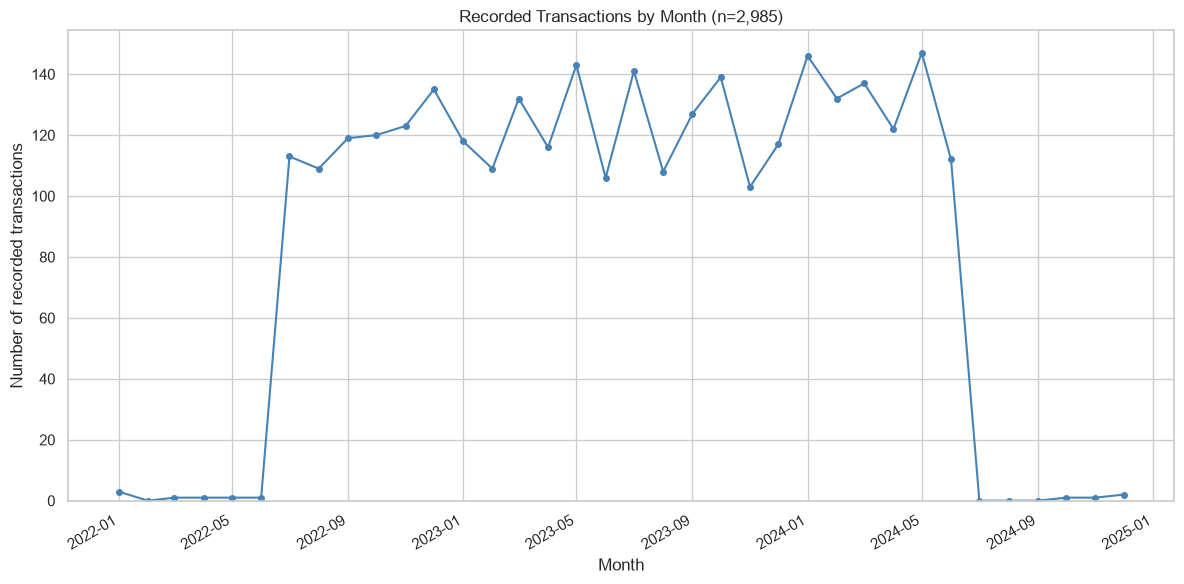

In [16]:
# Include every month, even those with no recorded transactions
all_months = pd.period_range(
    transactions["TransactionDate"].min().to_period("M"),
    transactions["TransactionDate"].max().to_period("M"),
    freq="M"
)

monthly_counts = monthly_counts.reindex(all_months, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    monthly_counts.index.to_timestamp(),
    monthly_counts.values,
    marker="o",
    markersize=4,
    color="steelblue"
)

ax.set_title(
    f"Recorded Transactions by Month (n={monthly_counts.sum():,})"
)
ax.set_xlabel("Month")
ax.set_ylabel("Number of recorded transactions")
ax.set_ylim(bottom=0)

fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(
    figures_folder / "05_monthly_transaction_counts.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


### Monthly Transaction Counts

A line chart was used to show changes in recorded transaction counts
over time. The chart includes 2,985 transactions dated from January 2022
to December 2024.

Most records fall between July 2022 and June 2024. Within this period,
monthly counts range from 103 to 147. May 2024 has the highest count
at 147, while November 2023 has the lowest at 103.

Only 11 transactions fall outside this main period. Their dates were
checked against the original Excel file and matched the source values
as read, so they were retained.

Months shown as zero contain no records in this dataset. This does
not confirm that FinMark had no transactions during those months.
The sharp changes at the edges of the main period cannot establish
business growth or decline because data coverage is uncertain.

For future machine learning, the completeness and consistency of date
coverage should be verified before forecasting or using time trends
to support decisions.

In [17]:
# Inspect social media fields
print("Social media columns:")
print(social_media.columns.tolist())

# Inspect platform and grouped sentiment counts
for column in ["Platform", "SentimentGrouped"]:
    print(f"\n{column}:")
    display(
        social_media[column]
        .fillna("Unknown")
        .value_counts()
        .rename("Count")
        .to_frame()
    )

Social media columns:
['CustomerID', 'InteractionID', 'InteractionDate', 'Platform', 'InteractionType', 'Sentiment', 'IDConflict', 'PlatformOriginal', 'SentimentOriginal', 'SentimentGrouped']

Platform:


,Count
Platform,
Instagram,911
Twitter,897
Facebook,883
Unknown,289



SentimentGrouped:


,Count
SentimentGrouped,
Positive,919
Negative,887
Neutral,867
Unknown,307


SentimentGrouped,Positive,Neutral,Negative,Unknown
Platform,,,,
Instagram,295,255,276,85
Twitter,251,273,271,102
Facebook,270,262,258,93
Unknown,103,77,82,27


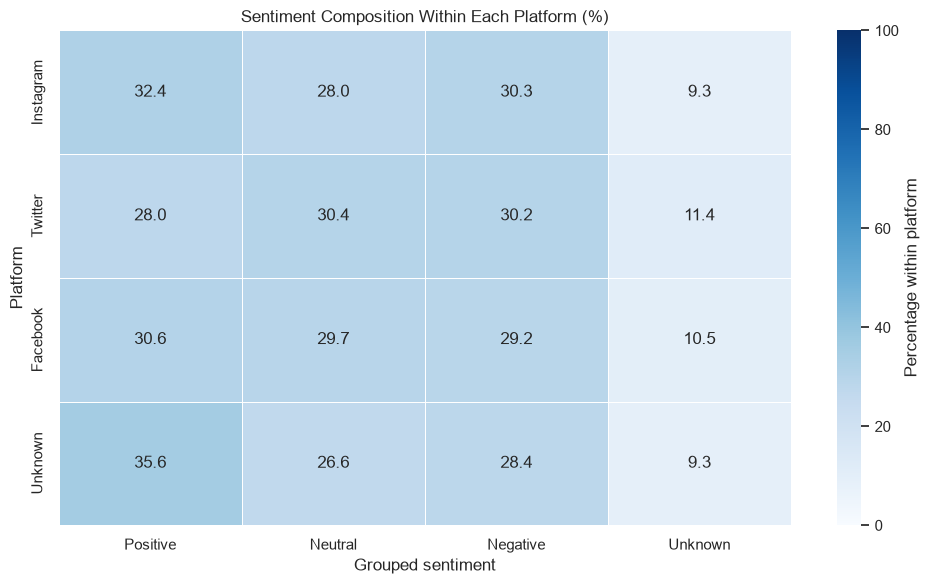

In [18]:
# Count sentiment groups within each platform
sentiment_counts = pd.crosstab(
    social_media["Platform"].fillna("Unknown"),
    social_media["SentimentGrouped"].fillna("Unknown")
).reindex(
    index=["Instagram", "Twitter", "Facebook", "Unknown"],
    columns=["Positive", "Neutral", "Negative", "Unknown"],
    fill_value=0
)

# Each platform row totals 100%
sentiment_percent = sentiment_counts.div(
    sentiment_counts.sum(axis=1), axis=0
) * 100

display(sentiment_counts)

fig, ax = plt.subplots(figsize=(10, 6))

sns.heatmap(
    sentiment_percent,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    linewidths=0.5,
    cbar_kws={"label": "Percentage within platform"},
    ax=ax
)

ax.set_title("Sentiment Composition Within Each Platform (%)")
ax.set_xlabel("Grouped sentiment")
ax.set_ylabel("Platform")

fig.tight_layout()
fig.savefig(
    figures_folder / "06_sentiment_by_platform_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Sentiment Distribution by Platform

A heatmap was used to compare sentiment percentages within each platform
across 2,980 social media interaction records. Each row totals approximately
100%, allowing comparison between platforms with different record counts.

Positive, neutral, and negative sentiments have relatively similar shares
across the three named platforms. Instagram has 32.4% positive sentiment,
Facebook has 30.6%, and Twitter has 28.0%.

Unknown sentiment accounts for 9.3% of Instagram records, 10.5% of Facebook
records, and 11.4% of Twitter records. Unknown represents unavailable
sentiment information and should not be treated as neutral.

The Unknown platform group contains 289 interactions. Its percentages
describe records without an available platform label.

For future machine learning, this chart helps assess sentiment balance
and missing information across platforms. These descriptive differences
do not establish that a platform causes more positive or negative sentiment.

In [19]:
# Verify that demographics has one record per customer
print(
    "Duplicate demographic CustomerIDs:",
    demographics["CustomerID"].duplicated().sum()
)

# Link valid amounts to observed customer ages
age_amount = amount_data.merge(
    demographics[["CustomerID", "AgeObserved"]],
    on="CustomerID",
    how="left",
    validate="many_to_one",
    indicator=True
)

print("Valid-amount records:", len(amount_data))
print("Records after linking:", len(age_amount))
print("No matching demographic record:",
      (age_amount["_merge"] == "left_only").sum())
print("Matched but observed age unavailable:",
      ((age_amount["_merge"] == "both")
       & age_amount["AgeObserved"].isna()).sum())

# Keep records with observed ages for the scatter plot
age_amount = age_amount.dropna(subset=["AgeObserved", "Amount"]).copy()
print("Records available for scatter plot:", len(age_amount))

Duplicate demographic CustomerIDs: 0
Valid-amount records: 2642
Records after linking: 2642
No matching demographic record: 27
Matched but observed age unavailable: 316
Records available for scatter plot: 2299


Pearson correlation: 0.0315
Unique customers: 1510


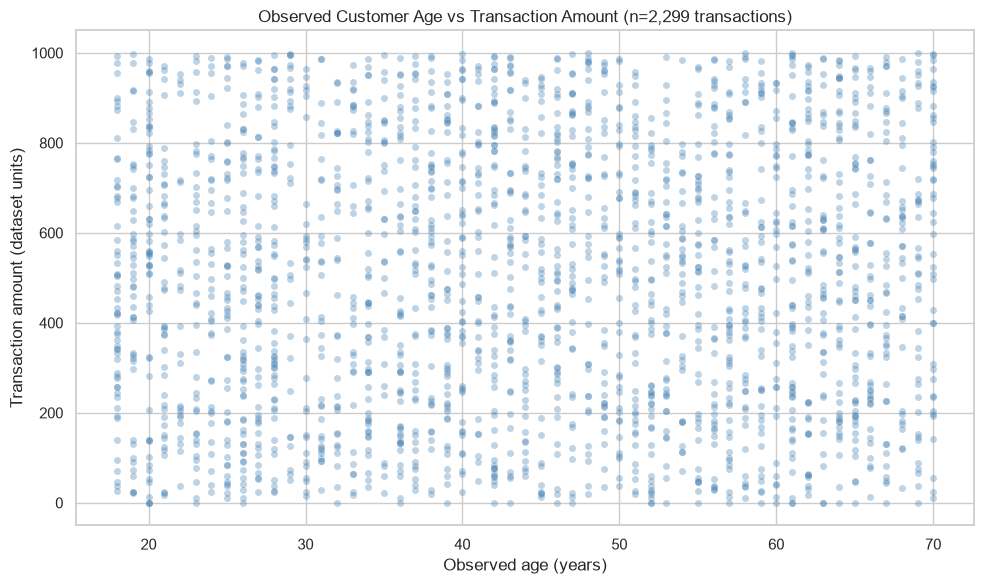

In [20]:
# Calculate the descriptive linear correlation using NumPy
age_amount_r = np.corrcoef(
    age_amount["AgeObserved"].to_numpy(),
    age_amount["Amount"].to_numpy()
)[0, 1]

print(f"Pearson correlation: {age_amount_r:.4f}")
print("Unique customers:", age_amount["CustomerID"].nunique())

# Each point represents one transaction
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(
    data=age_amount,
    x="AgeObserved",
    y="Amount",
    alpha=0.35,
    s=25,
    linewidth=0,
    color="steelblue",
    ax=ax
)

ax.set_title(
    f"Observed Customer Age vs Transaction Amount "
    f"(n={len(age_amount):,} transactions)"
)
ax.set_xlabel("Observed age (years)")
ax.set_ylabel("Transaction amount (dataset units)")

fig.tight_layout()
fig.savefig(
    figures_folder / "07_age_vs_transaction_amount.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Customer Age and Transaction Amount

A scatter plot was used to explore the relationship between observed
customer age and individual transaction amount.

Transactions were linked to demographics using CustomerID. The analysis
includes 2,299 transactions from 1,510 customers with both an observed
age and a valid amount. Of the 2,642 amount records, 27 had no matching
demographic record and 316 matched records without an observed age.

The points are widely scattered, with no clear upward or downward linear
pattern. The Pearson correlation is approximately 0.0315, indicating
very little linear association in this analysis subset.

Some customers have multiple transactions, so the points represent
transactions rather than independent customers.

For future machine learning, this result suggests that age alone has
little linear association with individual transaction amount. It does
not rule out nonlinear relationships or usefulness alongside other
variables, which would require further evaluation.

In [21]:
# Check exported chart files
chart_files = sorted(figures_folder.glob("*.png"))

print("Exported charts:", len(chart_files))
for file in chart_files:
    print(file.name)

Exported charts: 7
01_observed_age_distribution.png
02_transaction_amount_distribution.png
03_product_category_counts.png
04_amount_by_product_category.png
05_monthly_transaction_counts.png
06_sentiment_by_platform_heatmap.png
07_age_vs_transaction_amount.png
